# Classical Chinese semantic variation — revised feasibility pilot

**Targets:** 仁, 道, 天. **Collections:** Buddhist, Confucian, Medical, Daoist, and Historical when available.

This version filters **known compounds overlapping the exact target position**, saves an auditable exclusion log, and creates a review CSV. It does **not** automatically remove all non-philosophical senses: genuine standalone polysemy is part of the research question. Run top to bottom in your existing virtual environment.

## 1. Imports and settings

In [1]:
from pathlib import Path
from collections import Counter
import re, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
TARGET_WORDS = ["仁", "道", "天"]
MODEL_NAME = "ethanyt/guwenbert-base"
MAX_PER_WORD_COLLECTION = 100
MAX_PER_DOCUMENT = 20
CONTEXT_CHARS_EACH_SIDE = 120
OUTPUT_DIR = Path("pilot_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Notebook may be in the repo root, or in its parent directory.
repo_name = "CSCI700-Proposal-Classical-Chinese"
ROOT = Path.cwd() if Path.cwd().name == repo_name else Path.cwd() / repo_name
print("Corpus root:", ROOT.resolve())
assert ROOT.exists(), "Clone the GitHub repository or adjust ROOT above."


# Optional: after filling the review CSV, rerun with manual exclusions applied.
APPLY_MANUAL_REVIEW = False


Corpus root: D:\CU Boulder\CurrTopicsNLP\CSCI700-Proposal-Classical-Chinese


d:\CU Boulder\CurrTopicsNLP\CSCI700-Proposal-Classical-Chinese\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Discover available `.conllu` files and collection names

The directory search is recursive, so it can handle annotations in nested folders. Inspect the displayed folder names and adjust the mapping if needed.

In [2]:
files = sorted(ROOT.rglob("*.conllu"))
print("CoNLL-U files:", len(files))
print("Sample paths:", *[str(p.relative_to(ROOT)) for p in files[:12]], sep="\n  ")
assert files, "No .conllu files found. Check ROOT and repository contents."

COLLECTION_MAP = {"佛藏": "Buddhist", "儒藏": "Confucian", "醫藏": "Medical",
                  "医藏": "Medical", "道藏": "Daoist", "史藏": "Historical"}

def collection_for(path):
    parts = path.relative_to(ROOT).parts
    for part in parts[:-1]:
        for chinese, english in COLLECTION_MAP.items():
            if chinese in part:
                return english
    return None

summary = pd.DataFrame([{"file": str(p.relative_to(ROOT)), "collection": collection_for(p)} for p in files])
display(summary.groupby("collection", dropna=False).size().rename("files").to_frame())
if summary.collection.isna().any():
    print("Unclassified example paths:", summary[summary.collection.isna()].file.head(10).tolist())


CoNLL-U files: 40
Sample paths:
  佛藏\乾隆藏\大乘五大部外重译经\一切法高王经.conllu
  佛藏\乾隆藏\大乘五大部外重译经\七俱胝佛母所说准提陀罗尼经.conllu
  佛藏\乾隆藏\大乘五大部外重译经\不必定入定入印经.conllu
  佛藏\乾隆藏\大乘五大部外重译经\不空罥索咒心经.conllu
  佛藏\乾隆藏\大乘五大部外重译经\不空罥索心咒王经.conllu
  佛藏\乾隆藏\大乘五大部外重译经\不空罥索神变真言经.conllu
  佛藏\乾隆藏\大乘五大部外重译经\不空罥索神咒心经.conllu
  佛藏\乾隆藏\大乘五大部外重译经\不空罥索陀罗尼经.conllu
  佛藏\乾隆藏\大乘五大部外重译经\不退转法轮经.conllu
  佛藏\乾隆藏\大乘五大部外重译经\东方最胜灯王如来助护持世间神咒经.conllu
  儒藏\乐经\乐书.conllu
  儒藏\乐经\乐律全书.conllu


,files
collection,
Buddhist,10
Confucian,10
Daoist,10
Medical,10


## 3. Parse CoNLL-U and find occurrences

Counts **standalone annotated tokens** matching each character. We preserve sentence context and exact character offsets, rather than searching for substrings inside longer words. This avoids counting 道 within 道德, for example.

In [3]:
def iter_sentences(path):
    tokens = []
    for line in path.read_text(encoding="utf-8-sig").splitlines() + [""]:
        if not line.strip():
            if tokens:
                yield tokens
                tokens = []
            continue
        if line.startswith("#"):
            continue
        fields = line.split("\t")
        if len(fields) == 10 and fields[0].isdigit():
            tokens.append(fields[1])

records = []
for path in tqdm(files, desc="Reading corpus"):
    collection = collection_for(path)
    if collection is None:
        continue
    for sentence_id, tokens in enumerate(iter_sentences(path)):
        text = "".join(tokens)
        start = 0
        for token in tokens:
            if token in TARGET_WORDS:
                records.append({"word": token, "collection": collection,
                                "document": str(path.relative_to(ROOT)),
                                "sentence_id": sentence_id, "context": text,
                                "char_start": start})
            start += len(token)

occurrences = pd.DataFrame(records)
assert len(occurrences), "No target occurrences found. Inspect tokenization and folder mapping."
display(pd.crosstab(occurrences.word, occurrences.collection))
print("Distinct source documents:", occurrences.document.nunique())


Reading corpus: 100%|██████████| 40/40 [00:03<00:00, 12.71it/s]


collection,Buddhist,Confucian,Daoist,Medical
word,,,,
仁,9,430,103,153
天,1942,3179,1853,445
道,376,1368,2035,234


Distinct source documents: 40


## 4. Filter known compounds and audit segmentation

The corpus already identifies standalone CoNLL-U tokens. This additional filter removes **specific known compounds only when they overlap the exact occurrence**. The exclusions are logged. Inspect the review CSV and mark `yes`, `no`, or `uncertain`. To apply your `no` labels, set `APPLY_MANUAL_REVIEW = True` in settings and rerun from the top.

In [4]:
# Only exclude clearly unwanted larger lexical expressions. Edit this list conservatively.
# Examples such as 天命, 天地, 道德, 不仁 are NOT automatically excluded:
# they may be valid standalone tokens or analytically relevant.
EXCLUDE_EXPRESSIONS = {
    "仁": ["米仁", "薏仁", "杏仁", "桃仁", "麻木不仁"],
    "道": [],
    "天": [],
}

def overlapping_expression(row):
    text, start, word = row["context"], int(row["char_start"]), row["word"]
    end = start + len(word)
    for expression in EXCLUDE_EXPRESSIONS.get(word, []):
        pos = text.find(expression)
        while pos != -1:
            if pos <= start and end <= pos + len(expression):
                return expression
            pos = text.find(expression, pos + 1)
    return None

occurrences = occurrences.copy()
occurrences["occurrence_id"] = (
    occurrences["document"].astype(str) + "::" +
    occurrences["sentence_id"].astype(str) + "::" +
    occurrences["char_start"].astype(str) + "::" + occurrences["word"]
)
occurrences["excluded_expression"] = occurrences.apply(overlapping_expression, axis=1)
excluded = occurrences[occurrences.excluded_expression.notna()].copy()
excluded.to_csv(OUTPUT_DIR / "excluded_compound_occurrences.csv", index=False, encoding="utf-8-sig")
occurrences_filtered = occurrences[occurrences.excluded_expression.isna()].copy()
print("Original occurrences:", len(occurrences))
print("Excluded by compound rules:", len(excluded))
print("Remaining:", len(occurrences_filtered))
display(pd.crosstab(occurrences_filtered.word, occurrences_filtered.collection))
if len(excluded):
    display(excluded.groupby(["word", "excluded_expression"]).size().rename("count"))


Original occurrences: 12127
Excluded by compound rules: 26
Remaining: 12101


collection,Buddhist,Confucian,Daoist,Medical
word,,,,
仁,9,430,103,127
天,1942,3179,1853,445
道,376,1368,2035,234


word  excluded_expression
仁     杏仁                      2
      桃仁                     13
      米仁                      6
      麻木不仁                    5
Name: count, dtype: int64

In [5]:
# Save a reproducible, stratified manual-review sample, without replacement.
# Review the CSV outside Jupyter; mark valid_usage as yes/no/uncertain.
review_parts = []
for (_, _), group in occurrences_filtered.groupby(["word", "collection"]):
    review_parts.append(group.sample(n=min(10, len(group)), random_state=SEED))
review = pd.concat(review_parts, ignore_index=True)
def marked_context(row):
    s = int(row.char_start)
    return row.context[:s] + "【" + row.word + "】" + row.context[s+len(row.word):]
review["highlighted_context"] = review.apply(marked_context, axis=1)
review["valid_usage"] = ""
review["notes"] = ""
review_path = OUTPUT_DIR / "occurrence_review.csv"
# Do not overwrite human annotations on subsequent runs.
if not review_path.exists():
    review.to_csv(review_path, index=False, encoding="utf-8-sig")
    print("Created:", review_path)
else:
    print("Review file already exists; preserved:", review_path)
display(review[["word", "collection", "highlighted_context"]].head(15))

# Manual exclusions are optional; only 'no' is excluded, 'uncertain' is retained.
if APPLY_MANUAL_REVIEW:
    reviewed = pd.read_csv(review_path, dtype=str).fillna("")
    if not {"occurrence_id", "valid_usage"}.issubset(reviewed.columns):
        raise ValueError("Review CSV must contain occurrence_id and valid_usage columns")
    invalid_ids = set(reviewed.loc[reviewed.valid_usage.str.strip().str.lower() == "no", "occurrence_id"])
    occurrences_filtered = occurrences_filtered[~occurrences_filtered.occurrence_id.isin(invalid_ids)].copy()
    print("Manually rejected occurrences:", len(invalid_ids))


Created: pilot_outputs\occurrence_review.csv


,word,collection,highlighted_context
0,仁,Buddhist,大慈悲者愿垂哀愍。纳受此大清净月光宝华天冠常护显此不空大可畏明王央俱舍真言章句三昧耶。威德无...
1,仁,Buddhist,龙复报言今随意乐当令满足。作是语已即入海中。取如意宝珠奉施咒人。而发大愿以如意珠。施赡部洲一...
2,仁,Buddhist,尔时执金刚秘密主菩萨摩诃萨。即白观世音菩萨摩诃萨言。此不空罥索心王陀罗尼真言。广大解脱莲华曼...
3,仁,Buddhist,龙复报言今随意乐当令满足。作是语已即入海中。取如意宝珠奉施咒人。而发大愿以如意珠。施赡部洲一...
4,仁,Buddhist,常游一切真言明仙宫殿中住。又得秘密真言明仙三昧耶。所入一切神龙宫殿悉无障难。一切药叉罗刹神鬼...
5,仁,Buddhist,诵奋怒王真言一百八遍。则证大自在天神通三昧耶。寿延十八千岁。世间游行。于诸鬼神得无所畏。大自...
6,仁,Buddhist,有少宿植真菩提心善根种子如芥子者。彼人则得最胜成就。如是真实菩提心人。随其力办当作金铜舍利制...
7,仁,Buddhist,是时当以阏伽供养。又当以酥粳米饭团一千八团。加持护摩乞所求愿。则得火天手捧银器。满中有药奉真...
8,仁,Buddhist,一切佛心三昧耶。即是不空罥索心王陀罗尼真言三昧耶。不空罥索心王陀罗尼真言三昧耶。即是我心。我...
9,仁,Confucian,案万寳常之乐当时以为近前汉之乐则是隋代汉律虽已亡而乐声犹存也魏延陵得玉律当时以汉律较之所谓黄...


## 4. Balance the sample

Cap occurrences **per document first**, then per word × collection. This reduces dominance by one book. These are maximums; groups with fewer examples remain smaller.

In [6]:
parts = []
for (_, _, _), group in occurrences_filtered.groupby(["word", "collection", "document"]):
    parts.append(group.sample(n=min(len(group), MAX_PER_DOCUMENT), random_state=SEED))
per_document = pd.concat(parts, ignore_index=True)
parts = []
for (_, _), group in per_document.groupby(["word", "collection"]):
    parts.append(group.sample(n=min(len(group), MAX_PER_WORD_COLLECTION), random_state=SEED))
sampled = pd.concat(parts, ignore_index=True)
display(pd.crosstab(sampled.word, sampled.collection))


collection,Buddhist,Confucian,Daoist,Medical
word,,,,
仁,9,71,62,68
天,100,100,100,100
道,100,100,100,100


## 5. Load pretrained Classical Chinese RoBERTa

A **fast tokenizer** is required to locate the exact target span using character offsets. If the model does not provide a compatible fast tokenizer in your installation, this cell stops rather than silently assigning the wrong token embedding.

In [7]:
import torch
from transformers import AutoTokenizer, AutoModel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
assert tokenizer.is_fast, "Tokenizer does not support offsets. Choose a fast tokenizer/model combination."
model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
print("Device:", device, "| Hidden size:", model.config.hidden_size)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 33075.75it/s]
[transformers] RobertaModel LOAD REPORT from: ethanyt/guwenbert-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.decoder.weight    | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.decoder.bias      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device: cpu | Hidden size: 768


## 6. Embed each target occurrence

We crop a **centered character window** around each occurrence so a long sentence does not truncate away the target. For multi-subtoken targets, average their hidden states. By default, average the last four layers (a common exploratory choice).

In [ ]:
def embedding_for(row):
    text = row["context"]
    start = int(row["char_start"])
    word = row["word"]
    left = max(0, start - CONTEXT_CHARS_EACH_SIDE)
    right = min(len(text), start + len(word) + CONTEXT_CHARS_EACH_SIDE)
    snippet = text[left:right]
    local_start = start - left
    encoded = tokenizer(snippet, return_tensors="pt", return_offsets_mapping=True,
                        truncation=True, max_length=512)
    offsets = encoded.pop("offset_mapping")[0].tolist()
    positions = [i for i, (a, b) in enumerate(offsets)
                 if b > a and a < local_start + len(word) and b > local_start]
    if not positions:
        return None
    inputs = {k: v.to(device) for k, v in encoded.items()}
    with torch.inference_mode():
        output = model(**inputs, output_hidden_states=True)
        layers = torch.stack(output.hidden_states[-4:]).mean(dim=0)
        vec = layers[0, positions].mean(dim=0).cpu().numpy()
    return vec.astype("float32")

vectors, rows = [], []
for row in tqdm(sampled.to_dict("records"), desc="Embedding occurrences"):
    vector = embedding_for(row)
    if vector is not None:
        vectors.append(vector)
        rows.append(row)
assert vectors, "No embeddings were extracted; inspect tokenizer offsets."
X_all = np.vstack(vectors)
results = pd.DataFrame(rows).reset_index(drop=True)
np.save(OUTPUT_DIR / "contextual_embeddings.npy", X_all)
results.to_csv(OUTPUT_DIR / "sampled_occurrences.csv", index=False, encoding="utf-8-sig")
print("Embeddings:", X_all.shape)


Embedding occurrences: 100%|██████████| 1010/1010 [01:35<00:00, 10.59it/s]

Embeddings: (1010, 768)


## 7. Unsupervised clustering and school distributions

Fit clusters **separately for each word**, pooling collections and hiding collection labels during clustering. Cluster IDs are arbitrary. A fixed K=3 is exploratory, not a claim that each word has exactly three senses.

In [9]:
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans

results["cluster"] = -1
for word in TARGET_WORDS:
    mask = (results.word == word).to_numpy()
    X = normalize(X_all[mask])
    if len(X) < 3:
        continue
    labels = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(X)
    results.loc[mask, "cluster"] = labels
    print("\n", word)
    display(pd.crosstab(results.loc[mask, "collection"], labels, normalize="index").round(3))
results.to_csv(OUTPUT_DIR / "cluster_assignments.csv", index=False, encoding="utf-8-sig")



 仁


col_0,0,1,2
collection,,,
Buddhist,1.000,0.000,0.000
Confucian,0.718,0.282,0.000
Daoist,1.000,0.000,0.000
Medical,0.412,0.000,0.588



 道


col_0,0,1,2
collection,,,
Buddhist,0.87,0.04,0.09
Confucian,0.08,0.88,0.04
Daoist,0.02,0.22,0.76
Medical,0.42,0.50,0.08



 天


col_0,0,1,2
collection,,,
Buddhist,0.86,0.00,0.14
Confucian,0.00,0.93,0.07
Daoist,0.18,0.32,0.50
Medical,0.00,0.36,0.64


## 8. PCA plots by collection

PCA is for visualization; overlapping points or separated groups do not independently establish a difference in meaning.

C:\Users\Amara Tariq\AppData\Local\Temp\ipykernel_22972\3894103273.py:14: UserWarning: Glyph 20161 (\N{CJK UNIFIED IDEOGRAPH-4EC1}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Amara Tariq\AppData\Local\Temp\ipykernel_22972\3894103273.py:15: UserWarning: Glyph 20161 (\N{CJK UNIFIED IDEOGRAPH-4EC1}) missing from font(s) DejaVu Sans.
  fig.savefig(OUTPUT_DIR / f"pca_{word}.png", dpi=180)
d:\CU Boulder\CurrTopicsNLP\CSCI700-Proposal-Classical-Chinese\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20161 (\N{CJK UNIFIED IDEOGRAPH-4EC1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


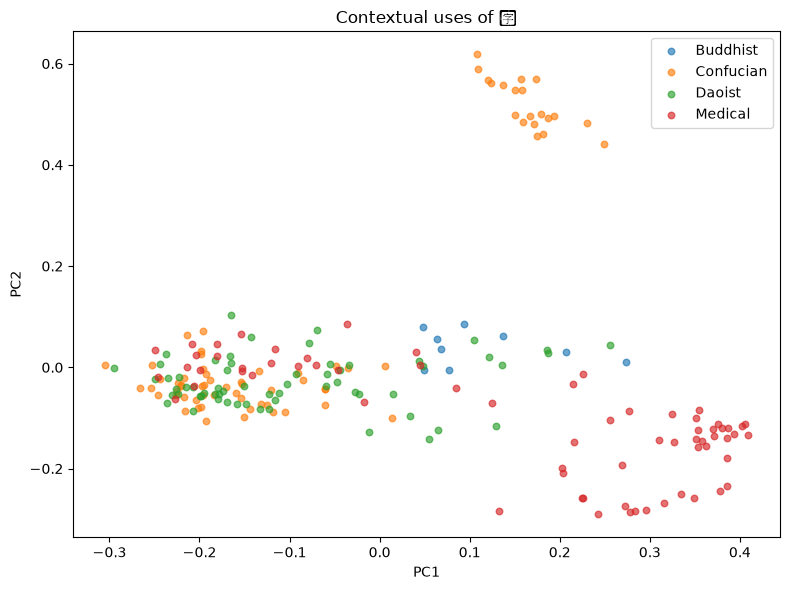

C:\Users\Amara Tariq\AppData\Local\Temp\ipykernel_22972\3894103273.py:14: UserWarning: Glyph 36947 (\N{CJK UNIFIED IDEOGRAPH-9053}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Amara Tariq\AppData\Local\Temp\ipykernel_22972\3894103273.py:15: UserWarning: Glyph 36947 (\N{CJK UNIFIED IDEOGRAPH-9053}) missing from font(s) DejaVu Sans.
  fig.savefig(OUTPUT_DIR / f"pca_{word}.png", dpi=180)
d:\CU Boulder\CurrTopicsNLP\CSCI700-Proposal-Classical-Chinese\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 36947 (\N{CJK UNIFIED IDEOGRAPH-9053}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


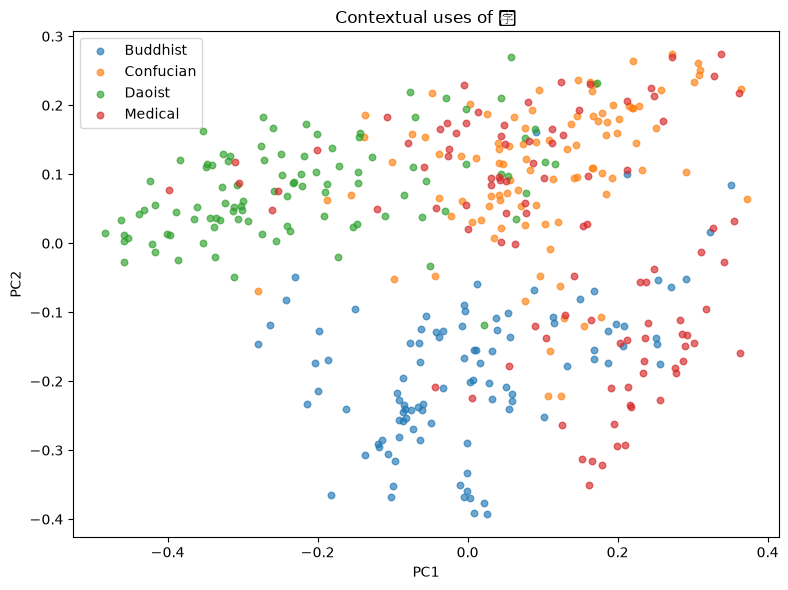

C:\Users\Amara Tariq\AppData\Local\Temp\ipykernel_22972\3894103273.py:14: UserWarning: Glyph 22825 (\N{CJK UNIFIED IDEOGRAPH-5929}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Amara Tariq\AppData\Local\Temp\ipykernel_22972\3894103273.py:15: UserWarning: Glyph 22825 (\N{CJK UNIFIED IDEOGRAPH-5929}) missing from font(s) DejaVu Sans.
  fig.savefig(OUTPUT_DIR / f"pca_{word}.png", dpi=180)
d:\CU Boulder\CurrTopicsNLP\CSCI700-Proposal-Classical-Chinese\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 22825 (\N{CJK UNIFIED IDEOGRAPH-5929}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


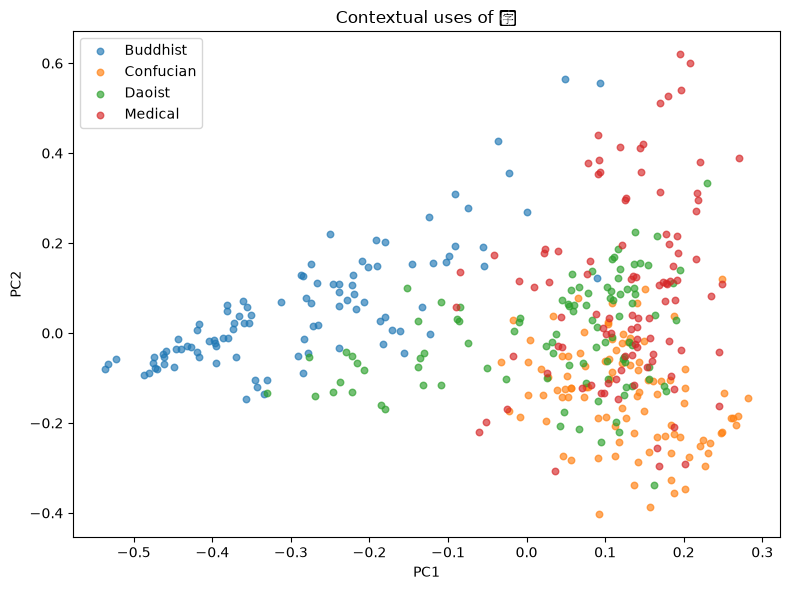

In [10]:
from sklearn.decomposition import PCA
for word in TARGET_WORDS:
    mask = (results.word == word).to_numpy()
    X = normalize(X_all[mask])
    if len(X) < 3:
        continue
    coords = PCA(n_components=2, random_state=SEED).fit_transform(X)
    fig, ax = plt.subplots(figsize=(8, 6))
    for collection in sorted(results.loc[mask, "collection"].unique()):
        m = (results.loc[mask, "collection"].to_numpy() == collection)
        ax.scatter(coords[m, 0], coords[m, 1], label=collection, s=22, alpha=0.65)
    ax.set(title=f"Contextual uses of {word}", xlabel="PC1", ylabel="PC2")
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"pca_{word}.png", dpi=180)
    plt.show()


## 9. School centroid cosine similarity

Centroids average normalized occurrence embeddings. High similarity means broadly similar model representations, **not necessarily identical philosophical senses**.

In [11]:
from sklearn.metrics.pairwise import cosine_similarity
for word in TARGET_WORDS:
    mask = (results.word == word).to_numpy()
    subset = results.loc[mask]
    X = normalize(X_all[mask])
    groups = sorted(subset.collection.unique())
    centroids = np.vstack([X[(subset.collection.to_numpy() == g)].mean(axis=0) for g in groups])
    matrix = pd.DataFrame(cosine_similarity(centroids), index=groups, columns=groups)
    print("\n", word)
    display(matrix.round(3))
    matrix.to_csv(OUTPUT_DIR / f"cosine_{word}.csv")



 仁


,Buddhist,Confucian,Daoist,Medical
Buddhist,1.000,0.772,0.819,0.790
Confucian,0.772,1.000,0.957,0.917
Daoist,0.819,0.957,1.000,0.933
Medical,0.790,0.917,0.933,1.000



 道


,Buddhist,Confucian,Daoist,Medical
Buddhist,1.000,0.908,0.895,0.927
Confucian,0.908,1.000,0.903,0.968
Daoist,0.895,0.903,1.000,0.903
Medical,0.927,0.968,0.903,1.000



 天


,Buddhist,Confucian,Daoist,Medical
Buddhist,1.000,0.853,0.899,0.867
Confucian,0.853,1.000,0.945,0.947
Daoist,0.899,0.945,1.000,0.959
Medical,0.867,0.947,0.959,1.000


## 10. Inspect contexts from every cluster

Human interpretation is necessary: clusters can reflect grammar, topic, genre, or author rather than word sense. Export examples for annotation.

In [12]:
examples = []
for (word, cluster), group in results.groupby(["word", "cluster"]):
    if cluster < 0:
        continue
    chosen = group.sample(n=min(8, len(group)), random_state=SEED)
    examples.append(chosen)
    print(f"\n{word} / cluster {cluster}")
    for _, r in chosen.iterrows():
        print(f"  [{r['collection']}] {r['document']}: {r['context'][:180]}")
if examples:
    pd.concat(examples).to_csv(OUTPUT_DIR / "contexts_for_review.csv", index=False, encoding="utf-8-sig")



仁 / cluster 0
  [Daoist] 道藏\正统道藏太平部\三洞珠囊.conllu: 《洞神经第十四》云：凡学长生存神明者，山仁水智，动静所依。依仁者，静而寿也；依智者，动而乐也。乐近水，寿如山。山居玩水，长生之方也。当投简送名，拜见山水之灵。灵皇帝君，佑护善人，使弘仁智，长生神仙也。八节日寅午时，朱书白槿简一枚，曰：曾孙某州郡县乡里位姓名，志求长生，移籍太清，改死录，着生符。计字满简，诣山向王烧香，发炉再拜，读简毕，再拜长跪，青纸裹，青丝缠
  [Confucian] 儒藏\乐经\乐律全书.conllu: 长治县八谏乡施庄里故俗説云前檐滴高平后檐滴长子谓此也殿西稍北二十歩有小坪周八十歩西北接连大坪周四百六十歩土有古城遗址谓之神农城城内旧有庙今废城下六十歩有二泉相去十余歩左泉白右泉清泉侧有井所谓神农井也二泉南流二十歩相合而南寰宇志云神农尝五谷之所上有神农城下有神农泉后魏风土记云神农城在羊头山其下有神农泉皆指此也地名井子坪有田可种相传神农得嘉谷于此始教播种谓之五谷
  [Daoist] 道藏\正统道藏太平部\三洞珠囊.conllu: 身若金刚，貌若瑠璃；圆光五明，头上紫气；胸前真字。此九好兼前七十二相，合成八十一好也。《金书仙志真记》及《后圣九玄道君列纪》并云：青童君曰：夫有骨箓则好仙。好仙之人，皆有其仙志。仙志之人，或疲或笃也。疲则先世善功不足也，笃则玄箓宿命将定也。大都天箓显於玄宫，则气候□於躯形；箓字彰於太极，则心神正於丹房。若生有金阙玉名者，则其人眼有日光，青齿白血。其为人也，则
  [Daoist] 道藏\正统道藏太平部\云山集.conllu: 丹药炼成人莫识，神符飞处鬼难窥。法身混合虚空界，妙用分明更不疑。像法立像明真便失真，朦胧昏眼更添尘。丹青自此遮玄藏，土木何年露法身。幻出因绿徒诳世，横生机巧暗绳人。馒神谭鬼弥天过，不畏阎家老子慎。教网入门戴上铁笼头，牵去牵来不自由。钳束只依吾教诫，封缄不许外参求。天堂妄想媒求福，地狱虚声谭作忧。久久熏成倡鬼例，妖邪惑魅死时休。趋时侯门似海我如鱼，悬箔高门一一
  [Daoist] 道藏\正统道藏太平部\三洞珠囊.conllu: 於口业能伏身心等，则随功次第生欲界六天。六天者，从太黄天至上明天为六天也。於六根中有犹入前尘者，有缘尘而不入者，有渐不复缘入者，凡三种。三六为十八，则生色界十八天。十八天者，从虚

## 11. Feasibility summary

Report: number of source documents and occurrences per collection; whether embeddings were extracted; cluster distributions and centroid similarities; and **examples where interpretation supports or contradicts semantic differences**. Avoid claims of statistical significance without additional testing. For the full project, add multiple texts per tradition, historical records, chronology/genre controls, and document-level robustness checks.

In [13]:
summary = results.groupby(["word", "collection"]).agg(
    occurrences=("word", "size"), documents=("document", "nunique")
).reset_index()
display(summary)
summary.to_csv(OUTPUT_DIR / "feasibility_summary.csv", index=False)
print("Saved outputs in:", OUTPUT_DIR.resolve())


,word,collection,occurrences,documents
0,仁,Buddhist,9,2
1,仁,Confucian,71,9
2,仁,Daoist,62,9
3,仁,Medical,68,8
4,天,Buddhist,100,10
5,天,Confucian,100,10
6,天,Daoist,100,10
7,天,Medical,100,10
8,道,Buddhist,100,9
9,道,Confucian,100,10


Saved outputs in: D:\CU Boulder\CurrTopicsNLP\CSCI700-Proposal-Classical-Chinese\pilot_outputs


## Interpretation and robustness checklist

- Report **before/after filtering** counts and per-collection document counts.
- Inspect cluster examples for semantic coherence; clusters are not inherently word senses.
- Check whether clusters reflect documents or grammatical roles rather than traditions.
- Small or imbalanced samples (especially 仁) should be interpreted cautiously.
- The manual review is a sampled audit; setting `APPLY_MANUAL_REVIEW` only excludes reviewed `no` rows, not all unseen errors.

In [15]:
import numpy as np
from pathlib import Path

# Load saved contextual embeddings
embeddings = np.load("pilot_outputs/contextual_embeddings.npy")

print("Embeddings loaded:", embeddings.shape)

Embeddings loaded: (1010, 768)


In [17]:
print("Results rows:", len(results))
print("Embedding rows:", len(embeddings))

assert len(results) == len(embeddings), (
    "Results and embeddings have different lengths!"
)

Results rows: 1010
Embedding rows: 1010


In [16]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize

word = "道"
mask = results["word"] == word
subset = results.loc[mask].copy()

X = normalize(embeddings[mask.to_numpy()])

examples = []

for cluster in sorted(subset["cluster"].unique()):
    cluster_mask = (subset["cluster"] == cluster).to_numpy()
    cluster_X = X[cluster_mask]

    centroid = cluster_X.mean(axis=0, keepdims=True)
    scores = cosine_similarity(cluster_X, centroid).ravel()

    cluster_rows = subset.loc[cluster_mask].copy()
    cluster_rows["similarity"] = scores

    # Select representative occurrences from different documents
    selected = (
        cluster_rows.sort_values("similarity", ascending=False)
        .drop_duplicates("document")
        .head(3)
    )

    for _, row in selected.iterrows():
        start = int(row["char_start"])
        text = row["context"]

        # Show 30 characters around the exact target
        left = max(0, start - 30)
        right = min(len(text), start + 31)

        highlighted = (
            text[left:start]
            + "【道】"
            + text[start + 1:right]
        )

        examples.append({
            "cluster": cluster,
            "context": highlighted,
            "document": row["document"]
        })

review = pd.DataFrame(examples)

display(review[["cluster", "context"]])

,cluster,context
0,0,到于彼处。文殊师利。如是之人既思惟已。即尔便乘如来神通发行彼【道】。文殊师利。于意云何。如是...
1,0,乞食，旋绕诵俱胝遍，即见无能胜菩萨，与愿为说妙法，示无上菩提【道】。或见诃利底母，将此人入自...
2,0,众生之界而取法界。无量众生。于旷劫中多所乏少。不能成就菩提之【道】。引诸众生到不退转。志求于...
3,1,缪戾如此况此外注之多讹舛者彼徒知备数制器为实用而不知与声音之【道】相隔万里实空言也夫空言虽精...
4,1,天道】此班固取刘歆三统厯之説为志也律厯相通故以律起厯则三防之【道】着焉而算用中法月举中气推厯...
5,1,事根本也纪者度也量者量也柄者权衡也故协时月正日与同律度量衡其【道】相为经纬也帝曰夔命汝典乐教...
6,2,疗为事，今剑南、江表，此道行焉。所以称之为道士者，以其务营常【道】故也。至於法衣，非无差降。...
7,2,云：宁先生毛身，广耳，被发也。《老子道德经》云：头发茂盛，得【道】之根；手足汗津，精气充盈；...
8,2,黄央者，乃为木金水火土也，而为阴阳阳阴之祖炁矣。祖炁者，乃为【道】之一也。人能抱阳守一，而得...
